# Distinguir complejidad secuencial y volatilidad cambiante

**Nivel:** 2. **Requisitos previos:** Las lecciones anteriores de este tema; arrays NumPy y evaluación temporal. **Tiempo de lectura:** 40 minutos.

**Pregunta:** ¿Qué miden los diagnósticos de complejidad del orden y volatilidad de la escala en un control generado y un extracto eléctrico auténtico, y qué conclusiones no justifican?

## Objetivos

Calcule entropía con tolerancia original fija, examine frases binarias, compare inversión temporal y repita el ajuste robusto con semilla local. Identifique estimaciones ausentes antes de interpretar una curva.

## Preparación

El entorno incluye la implementación de secuencias, sus bibliotecas numéricas y el estimador robusto con semilla. Todas las entradas del caso trabajado están comprometidas. Un índice representa el mismo intervalo original a lo largo de la lección. Esto importa cuando un bloque reducido reúne varias observaciones: la escala es una operación sobre los datos originales, no una etiqueta añadida a un eje gráfico remuestreado.

pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
pip install forecastscope==0.1.4


In [1]:
# Configura la sesión y omite solo el aviso conocido del control de formas repetidas.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file())
sys.path.insert(0, str(root / "data-pipeline"))
from engine.analysis.nonlinear import chaos_measures
from forecastscope.diagnostics.volatility import arch_lm, garch, rolling_volatility, box_cox
from engine.analysis.sequence import matrix_profile, sequence_report
from engine.analysis.sequence import multiscale_entropy, time_reversal
from engine.analysis.atlas import prefix_features, associations, by_adjust
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-sequence-lessons"
warnings.filterwarnings("ignore", message="A large number of values in.*", category=UserWarning)
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "stumpy", "antropy", "nolds", "pycatch22", "scikit-learn",
            "statsforecast", "lightgbm", "mlforecast", "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))

# Carga la fuente observada una vez; las celdas posteriores operan científicamente.
electricity_values = np.loadtxt(root / "data/examples/electricity_sample.csv",
                                delimiter=",", skiprows=1, usecols=2)

print("ForecastScope", importlib.metadata.version("forecastscope"))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
stumpy 1.14.1
antropy 0.2.2
nolds 0.6.3
pycatch22 0.4.5
scikit-learn 1.9.1
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0
ForecastScope 0.1.4


## Datos

Los controles de entropía e inversión usan BRKV_level_shift, una secuencia explícitamente sintética leída sin reducción desde sequence.values en `data/derived/BRKV_level_shift/analysis.json`. ChronoScope es propietario del generador determinista con semilla 42 (`data-pipeline/engine/cases/forecast_cases.py`, MIT); sus índices no son fechas. El cálculo separado de volatilidad usa el extracto observado MT_010 de UCI (https://doi.org/10.24432/C58C86, CC BY 4.0), en `data/examples/electricity_sample.csv`. Cada y suma cuatro lecturas en kW: las diferencias y desviaciones condicionales conservan estas unidades de la fuente y no representan energía.


In [2]:
# Lee cada observación original del caso sintético con cambio estructural.
analysis = json.loads((root / "data/derived/BRKV_level_shift/analysis.json").read_text(encoding="utf-8"))
values = np.array(analysis["sequence"]["values"], dtype=float)
print('Observaciones originales:', len(values))


Observaciones originales: 300


## Método

La entropía multiescala de Costa forma una secuencia reducida por escala promediando bloques sin superposición. Una escala de cuatro conserva la media de cada bloque sucesivo de cuatro observaciones y descarta únicamente el bloque terminal incompleto. Luego compara patrones cortos de esa secuencia. El orden es dos: se pregunta si patrones similares de dos observaciones mantienen su similitud al añadir una tercera, excluyendo autocoincidencias de ambos conteos.


In [3]:
# Conserva fija la tolerancia original al agregar en cuatro escalas.
entropy = multiscale_entropy(values, scales=(1, 2, 4, 8))
print('Tolerancia original:', round(entropy["scales"][0]["tolerance"], 4))
for row in entropy["scales"]:
    print('Escala', row["scale"], "n", row["n"], "SampEn", row["entropy"])


Tolerancia original: 1.6917
Escala 1 n 300 SampEn 1.2522944746943416
Escala 2 n 150 SampEn 0.9624020838335607
Escala 4 n 75 SampEn 0.3980301296206462
Escala 8 n 37 SampEn 0.6931471805599453


La tolerancia se fija como fracción de la desviación original. No se reduce ni amplía por separado con cada secuencia promediada. Recalcularla en cada escala podría hacer que algunas curvas parecieran artificialmente similares y respondería otra pregunta. La salida incluye pares coincidentes y observaciones disponibles, lo que permite interpretar la ausencia de una estimación. Puede faltar porque quedan pocas observaciones o porque ninguna extensión de plantilla coincide; ninguna situación significa complejidad cero.


In [4]:
# Distingue una entropía cero legítima de la falta de observaciones agregadas.
constant = multiscale_entropy(np.ones(100), scales=(1, 2, 4, 8))
print('Entropía de la serie constante en escala uno:', constant["scales"][0]["entropy"])
print('Estimación agregada corta:', constant["scales"][-1]["entropy"])


Entropía de la serie constante en escala uno: -0.0
Estimación agregada corta: None


El control constante distingue la imposibilidad de estimar de un cero legítimo. Cuando hay suficientes observaciones, coinciden todos los pares y sus extensiones, por lo que la entropía es cero. En una escala con menos de veinte observaciones, el producto decide no informar la estimación. Este límite es una regla declarada de presentación, no un teorema que garantice resultados fiables en muestras mayores. Incluso una muestra más larga puede tener conteos inestables cerca del umbral de similitud.

La asimetría de reversión temporal examina un momento de tercer orden con rezago. Usamos rezago dos y repetimos la operación invirtiendo las observaciones. El resultado bruto tiene unidades cúbicas; estandarizar antes del cálculo elimina ubicación y escala. Invertir todo el orden intercambia ambos términos y cambia el signo, proporcionando una comprobación estructural exacta. Eso no produce un valor p ni establece que una diferencia finita sea estadísticamente significativa.


In [5]:
# Calcula el mismo estadístico de rezago con las observaciones directas e invertidas.
forward = time_reversal(values, lag=2)
backward = time_reversal(values[::-1], lag=2)
print('Estadístico estandarizado de la secuencia original:', round(forward["standardized"], 6))
print('Estadístico estandarizado invertido:', round(backward["standardized"], 6))


Estadístico estandarizado de la secuencia original: 0.000749
Estadístico estandarizado invertido: -0.000749


Lempel-Ziv adopta otra representación. Los valores superiores a la mediana se convierten en uno y los restantes en cero. La secuencia binaria se analiza mediante frases nuevas. Conservamos el conteo de frases y su normalización asintótica, c(n) log2(n)/n. Una muestra finita puede dar un resultado normalizado superior a uno y no se recorta. La codificación elimina amplitudes y asigna los empates de manera consistente; cambiar el umbral o el alfabeto cambia el método.


In [6]:
# Inspecciona las frases binarias umbralizadas por la mediana y su normalización.
symbolic = sequence_report(values, seasonality=12)
print('Cantidad de frases binarias:', symbolic["lempel_ziv"]["raw"])
print('Cantidad normalizada de frases:', round(symbolic["lempel_ziv"]["normalized"], 4))


Cantidad de frases binarias: 13
Cantidad normalizada de frases: 0.3566


Un cambio positivo de unidades y un desplazamiento deberían conservar el orden respecto a la mediana y las estadísticas estandarizadas, salvo precisión numérica. También multiplican la tolerancia original de entropía por el mismo factor que las observaciones. Ejecutamos nuevamente la implementación después de la transformación, sin suponer que todas las magnitudes son adimensionales. El momento bruto de tercer orden no debe compararse entre unidades ignorando su transformación cúbica.


In [7]:
# Repite los cálculos después de una conversión afín positiva de unidades.
converted = sequence_report(values*10+100, seasonality=12)
print('Frases después de convertir unidades:', converted["lempel_ziv"]["raw"])
print('Entropía transformada en escala uno:', converted["multiscale_entropy"]["scales"][0]["entropy"])


Frases después de convertir unidades: 13
Entropía transformada en escala uno: 1.2522944746943416


### Variabilidad y volatilidad condicional en observaciones auténticas

La entropía resume regularidad después de fijar codificación o tolerancia; la volatilidad condicional pregunta por la escala de una innovación. Usamos directamente ForecastScope 0.1.4 sobre las primeras diferencias eléctricas, conservando las 479 diferencias consecutivas. Una diferencia que termina en la fila original t sigue alineada con t; retirar valores no finitos antes de calcularla cambiaría su interpretación temporal. Aquí todos los valores admitidos son finitos. La media de diferencias se estima dentro de la muestra. Puede permanecer el patrón día/noche: ni un p-valor ARCH pequeño ni una recurrencia GARCH prueban volatilidad estocástica tras especificar correctamente la media condicional. Son cálculos descriptivos del extracto finito.

La varianza condicional GARCH(1,1) sigue

$$\sigma_t^2=\omega+\alpha\epsilon_{t-1}^2+\beta\sigma_{t-1}^2.$$

Epsilon es el cambio centrado, omega el intercepto de varianza, alpha el coeficiente del choque cuadrático y beta el coeficiente de varianza condicional rezagada; la persistencia informada es alpha+beta (Bollerslev, 1986, https://doi.org/10.1016/0304-4076(86)90063-1). El paquete devuelve sigma como desviación estándar en las unidades originales del cambio. Los parámetros y la verosimilitud pertenecen a la escala de estimación; fit_scale registra el multiplicador aplicado. Comparar omega entre conversiones sin deshacer el multiplicador sería engañoso. Mostramos escala y persistencia sin interpretar un ajuste corto como modelo causal de energía.


Versión de ForecastScope: 0.1.4
Rezagos, estadístico y p-valor ARCH: 12 59.797866 2.457e-08
Escala de ajuste y persistencia: 1.0 0.802868
Clases de avisos numéricos: []


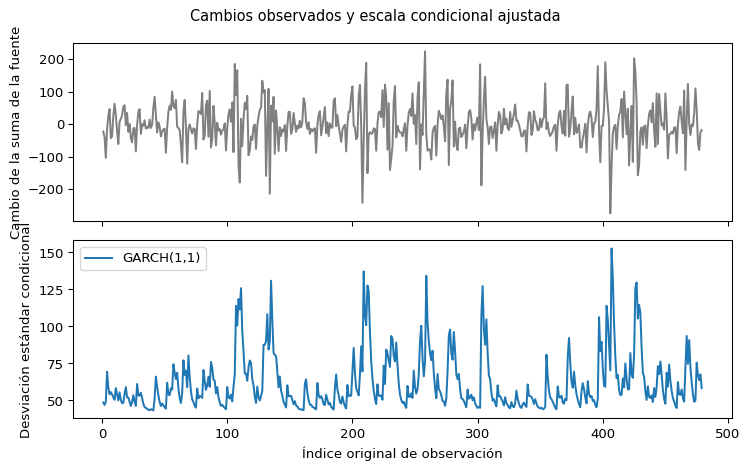

In [8]:
# Separa la descripción del segundo momento del experimento de error predictivo.
changes = np.diff(electricity_values)
test = arch_lm(changes, nlags=12)
with warnings.catch_warnings(record=True) as volatility_notices:
    warnings.simplefilter("always")
    fitted_garch = garch(changes, p=1, q=1)
print("Versión de ForecastScope:", importlib.metadata.version("forecastscope"))
print("Rezagos, estadístico y p-valor ARCH:", test.nlags, round(test.lm_stat, 6), f"{test.lm_pvalue:.3e}")
print("Escala de ajuste y persistencia:", fitted_garch.fit_scale, round(fitted_garch.persistence, 6))
print("Clases de avisos numéricos:", sorted({type(item.message).__name__ for item in volatility_notices}))
fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
indices = np.arange(1, len(electricity_values))
axes[0].plot(indices, changes, color="grey")
axes[0].set(ylabel="Cambio de la suma de la fuente")
axes[1].plot(indices, fitted_garch.conditional_volatility, label="GARCH(1,1)")
axes[1].set(xlabel="Índice original de observación", ylabel="Desviación estándar condicional")
axes[1].legend()
fig.suptitle('Cambios observados y escala condicional ajustada', fontsize=11)
fig.tight_layout()
plt.show()


El panel superior conserva cambios observados; el inferior muestra desviación estándar condicional ajustada, con las mismas unidades. Una sigma grande indica mayor escala bajo ese modelo, no mayor cambio esperado ni prueba de ruptura estructural. Se imprimen las clases de avisos numéricos: problemas de convergencia restringen la interpretación aunque exista una curva. ARCH usa 12 cambios consecutivos y su p-valor depende de supuestos sobre residuos.

### Sensibilidad a la ventana de volatilidad y la transformación

Comparamos desviaciones muestrales móviles con ventanas 12, 24 y 48 sobre los mismos cambios. Una ventana mayor reacciona más lentamente y omite más valores iniciales: el prefijo indefinido permanece ausente sin desplazar el eje. Es sensibilidad, no selección de la curva más atractiva. Por separado llamamos Box-Cox sobre niveles originales con logaritmo fijo y MLE ajustada. Si hace falta un desplazamiento al dominio positivo se devuelve explícitamente; el eje transformado no puede rotularse como potencia original. El desplazamiento depende solo de valores entregados: en operación se ajusta con historia disponible y se conserva para valores futuros.


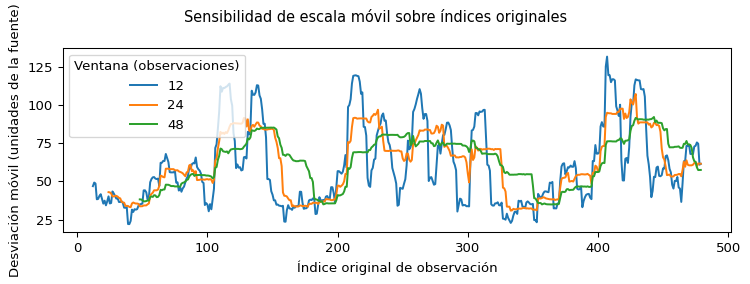

log lambda y desplazamiento al dominio positivo: 0.0 0.0
mle lambda y desplazamiento al dominio positivo: -0.177277 0.0


In [9]:
# Conserva ventanas iniciales ausentes al comparar estimaciones de escala.
fig, ax = plt.subplots()
for window in (12, 24, 48):
    rolling = rolling_volatility(changes, window=window)
    ax.plot(indices, rolling["rolling_std"], label=str(window))
ax.set(xlabel="Índice original de observación", ylabel="Desviación móvil (unidades de la fuente)")
ax.legend(title="Ventana (observaciones)")
fig.suptitle('Sensibilidad de escala móvil sobre índices originales', fontsize=11)
fig.tight_layout()
plt.show()
for method in ("log", "mle"):
    transformed = box_cox(electricity_values, method=method)
    print(method, "lambda y desplazamiento al dominio positivo:", round(transformed.lam, 6), transformed.shift)


Las curvas móviles intercambian respuesta rápida por estabilidad y difieren de la recurrencia GARCH ajustada. Sus huecos iniciales son consecuencias intencionales de exigir ventanas completas. Una lambda Box-Cox cercana a cero sugiere una transformación aproximadamente logarítmica del extracto, pero no elimina estructura estacional ni dependencia. Elegir una transformación después de observar errores reservados o mostrar volatilidad dentro de muestra no calibra una banda predictiva.

### Úsalo con tus propios datos: ForecastScope

Entrega una secuencia finita unidimensional en orden cronológico e indica si contiene niveles, retornos o diferencias. Conserva la correspondencia de cada transformación con las filas originales. Llama arch_lm con nlags explícito menor que la muestra residual utilizable; rolling_volatility con una ventana completa justificada, y garch después de considerar media condicional y avisos numéricos. Inspecciona longitud de conditional_volatility, fit_scale y significado de parámetros antes de graficar. Una secuencia constante, historia corta o verosimilitud Box-Cox indefinida exige una alternativa documentada, no un p-valor inventado. Se consume la API publicada de ForecastScope; el notebook no contiene un ajuste GARCH de reemplazo.


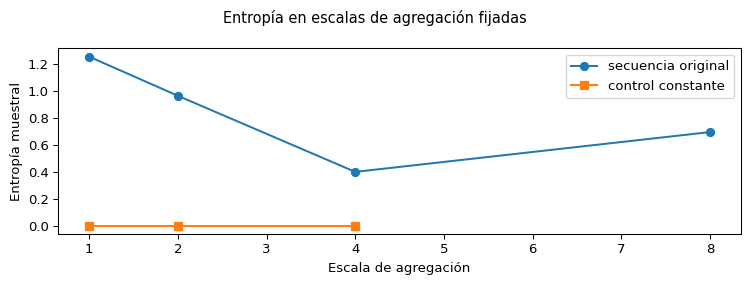

In [10]:
# Compara el caso observado y el control constante con la misma política de escala.
fig, ax = plt.subplots()
ax.plot([r["scale"] for r in entropy["scales"]],
        [r["entropy"] for r in entropy["scales"]], marker="o", label='secuencia original')
ax.plot([r["scale"] for r in constant["scales"]],
        [r["entropy"] for r in constant["scales"]], marker="s", label='control constante')
ax.set(xlabel='Escala de agregación', ylabel='Entropía muestral')
ax.legend()
fig.suptitle('Entropía en escalas de agregación fijadas', fontsize=11)
fig.tight_layout()
plt.show()


Las curvas comparten una convención de tolerancia, pero describen secuencias diferentes. La curva del caso puede cambiar al eliminarse detalles de orden mediante promedios; el control constante permanece en cero donde la regla de tamaño permite estimarlo. Los extremos ausentes deben seguir viéndose como ausentes. Una curva descendente no demuestra aleatoriedad, y una curva persistente tampoco prueba información predictiva de largo alcance en este registro finito y no estacionario.


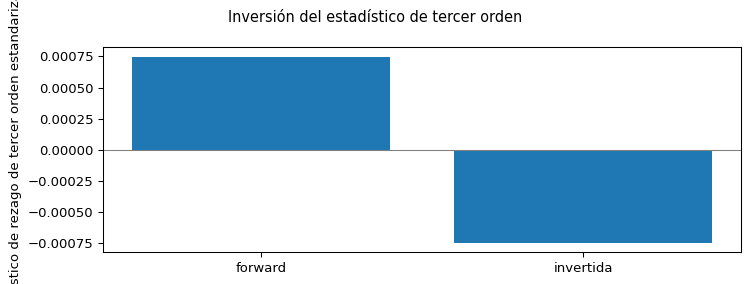

In [11]:
# Muestra el estadístico estandarizado con signo en ambas direcciones.
fig, ax = plt.subplots()
ax.bar(["forward", 'invertida'], [forward["standardized"], backward["standardized"]])
ax.axhline(0, color="grey", linewidth=.8)
ax.set(ylabel='Estadístico de rezago de tercer orden estandarizado')
fig.suptitle('Inversión del estadístico de tercer orden', fontsize=11)
fig.tight_layout()
plt.show()


Las barras muestran el cambio de signo ante una transformación conocida del orden. Sus magnitudes corresponden a observaciones estandarizadas y no heredan unidades cúbicas de la fuente. La simetría aparente es una propiedad de la estadística al invertir el orden, no evidencia independiente de una dirección física del tiempo. Interpretar diferencias estadísticas exigiría un experimento de sustitutos u otra prueba correctamente especificada bajo una hipótesis nula concreta.

Respuesta: la tolerancia del caso es 1.6917 y permanece fija entre escalas. El control constante tiene entropía cero en escala uno, mientras que su extremo corto no está disponible. Las salidas distinguen un cero calculado de un límite de estimación. El conteo simbólico conserva su valor al convertir unidades positivas y la estadística estandarizada cambia de signo al invertir el orden. Así se observa la utilidad de varios diagnósticos sin confundirlos con estimaciones intercambiables de una única cantidad oculta llamada complejidad.

El ajuste no lineal con semilla responde otra pregunta de reproducibilidad. Su regresión robusta usa un estado aleatorio local sobre los datos logarítmicos expuestos por la biblioteca. Repetir el ajuste no debería depender de sorteos realizados por otro usuario de la función. El pipeline deriva una semilla de la identidad del caso y la semilla suministrada, y conserva la condición de sustitutos antes de emitir un dictamen de caos. La repetibilidad numérica es una propiedad necesaria de la implementación, no prueba de que el proceso observado sea determinista.


In [12]:
# Repite estimaciones no lineales robustas con una semilla local explícita.
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", category=SyntaxWarning, message="invalid escape sequence.*")
    first_fit = chaos_measures(values, seed=42)
    second_fit = chaos_measures(values, seed=42)
print('Estimaciones robustas repetidas idénticas:', first_fit == second_fit)
print('Dimensión de correlación:', round(first_fit.corr_dim, 6))


Estimaciones robustas repetidas idénticas: True
Dimensión de correlación: 1.570235


### Limitaciones

El caso incluye niveles cambiantes y una cantidad finita de observaciones. Los resúmenes globales pueden combinar varios regímenes en lugar de identificar un mecanismo estable. La simbolización binaria oculta amplitudes y puede ser sensible a empates. Los conteos dependen de orden, tolerancia y longitud. Por ello, el estudio M4 usa estas magnitudes como características de prefijos bajo un protocolo declarado, contrasta su relación con errores posteriores y conserva los resultados negativos sin interpretar cualquier curva irregular como estructura predictiva.

### Sensibilidad a la tolerancia de coincidencia

En la escala $s$ el algoritmo calcula medias de bloques disjuntos y descarta el último grupo incompleto.

$$
x^{(s)}_j=\frac{1}{s}\sum_{k=0}^{s-1}x_{js+k},
\qquad 0\le j<\lfloor n/s\rfloor .
$$

Sea $B_m$ el número de pares distintos y no ordenados de patrones de longitud $m$ cuya máxima diferencia por coordenada no supera $r$. Sea $A_{m+1}$ el conteo equivalente después de extenderlos una observación. La implementación restringe ambos conteos a posiciones que admiten la extensión.

$$
\operatorname{SampEn}(m,r)=-\log\!\left(\frac{A_{m+1}}{B_m}\right),
\qquad A_{m+1},B_m>0.
$$

El cociente es la fracción de pares coincidentes que sigue coincidiendo al incluir la observación siguiente. Una tolerancia positiva admite valores iguales y cercanos. Aumentarla no puede reducir ninguno de los conteos para una secuencia y escala fijas. El cociente sí puede subir o bajar porque ambos conteos pueden crecer en proporciones distintas. Una tolerancia mayor no garantiza un cambio de entropía en un sentido determinado.


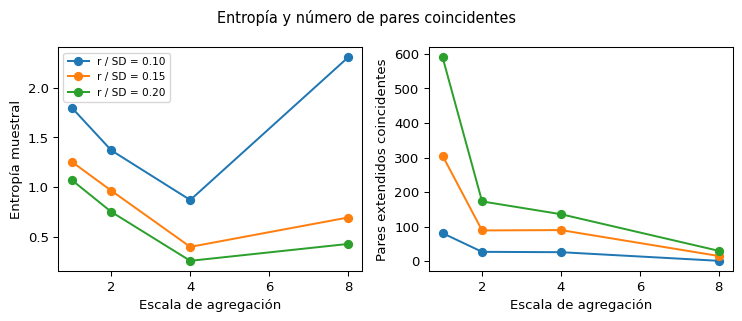

In [13]:
# Sigue la entropía y los pares coincidentes bajo tres tolerancias declaradas.
fig, axes = plt.subplots(1, 2, figsize=(8, 3.4))
for ratio in (0.10, 0.15, 0.20):
    rows = multiscale_entropy(values, scales=(1, 2, 4, 8), tolerance_ratio=ratio)["scales"]
    scales = [row["scale"] for row in rows]
    axes[0].plot(scales, [row["entropy"] for row in rows], marker="o", label=f"r / SD = {ratio:.2f}")
    axes[1].plot(scales, [row["matching_m_plus_one"] for row in rows], marker="o")
axes[0].set(xlabel='Escala de agregación', ylabel='Entropía muestral')
axes[1].set(xlabel='Escala de agregación', ylabel='Pares extendidos coincidentes')
axes[0].legend(fontsize=8)
fig.suptitle('Entropía y número de pares coincidentes', fontsize=11)
fig.tight_layout()
plt.show()


El panel izquierdo muestra cómo varía la entropía con las tres tolerancias declaradas. El derecho muestra cuánta evidencia sostiene cada estimación al contar coincidencias extendidas. Compare los paneles en la misma escala de agregación. Con pocas coincidencias extendidas, el cociente es sensible a pares individuales. Si el conteo cae a cero, la estimación queda ausente. Las escalas mayores dejan secuencias más cortas. Esto reduce el número de pares posibles, aunque promediar también puede volver los valores más parecidos. Un gráfico solo de entropía ocultaría esos efectos simultáneos.

Este análisis cambia únicamente una fracción de la desviación estándar original. Cada línea conserva la misma tolerancia absoluta en sus cuatro escalas. Si recalibra la tolerancia sobre cada secuencia agregada, identifique esa elección como otro estimador y explique su propósito. Examinar estos parámetros después de observar un caso permite diagnosticar fragilidad. No justifica elegir la curva que más se parezca a un mecanismo esperado.

### Extiende el experimento a tus propios datos

Elija un segmento regularmente espaciado con duración, frecuencia y unidades conocidas. Declare si las lecturas faltantes interrumpen la secuencia o se imputan, y registre su posición y tratamiento antes de calcular medidas con rezagos. Exprese las escalas en duraciones físicas y compruebe que cada duración conserve suficientes bloques. Evite contar segmentos adyacentes superpuestos como datos independientes por comenzar en instantes distintos. Si el diagnóstico influye en una decisión, reserve otro período para la comparación.

Incluya dos controles. Un segmento constante ejercita el límite entre cero y una estimación ausente. Un cambio positivo de unidades comprueba si la tolerancia y los valores cambian en la misma proporción. Si la pregunta se refiere al orden, invierta el segmento original y compare el signo del momento estandarizado, manteniendo fijas las demás decisiones. La cuantización y los empates pueden cambiar el conteo binario de frases aun cuando dos calibraciones de sensor parezcan casi iguales. Conserve los valores originales y registre el umbral para poder examinar ese efecto más adelante.

Compare los conteos antes de comparar entropías publicadas por dos estudios. El orden de los patrones, la norma y el tratamiento de coincidencias consigo mismo pueden cambiar el denominador. Informe estas decisiones, la tolerancia y el tamaño muestral por escala.

### Reproducir

Ejecute las llamadas y ambas figuras en orden. Compruebe tolerancia, cero y extremo ausente del control, conteo de frases y estimaciones robustas repetidas. Las pruebas independientes de conteo de pares y conservación del generador aleatorio cubren propiedades adicionales; la lección aporta un ejemplo interpretable sin reemplazar esas pruebas por un gráfico.


## Resultados

**Respuesta:** El conteo de frases binarias es 13 y su normalización es 0.3566. La curva de entropía cambia con la escala bajo una tolerancia original fija, mientras el conteo de frases binarias describe otra representación. Invertir el orden cambia el signo del estadístico. Ninguno de estos valores descriptivos certifica por sí solo caos, significancia o precisión de pronóstico. La sección de volatilidad utiliza otra secuencia eléctrica auténtica: su desviación condicional ajustada describe escala en unidades de la fuente; entropía y frases binarias describen representación y orden del control generado. Son entradas y preguntas distintas; ningún cálculo por sí solo establece caos ni intervalos futuros calibrados.

## Resumen

Entropía, frases y momentos con rezago descartan información distinta. Unidades, valores ausentes y condiciones de repetibilidad forman parte del resultado.

## Referencias

[Richman y Moorman sobre entropía muestral](https://doi.org/10.1152/ajpheart.2000.278.6.H2039).

Costa, Goldberger y Peng, DOI 10.1103/PhysRevLett.89.068102. Lempel y Ziv, DOI 10.1109/TIT.1976.1055501. La definición tsfresh especifica el momento con rezago, y nolds documenta los datos de ajuste utilizados por el adaptador con semilla.

[Nolds fitting documentation](https://cschoel.github.io/nolds/nolds.html).

- https://doi.org/10.1103/PhysRevLett.89.068102

- https://doi.org/10.1109/TIT.1976.1055501

- https://doi.org/10.24432/C58C86

- https://pypi.org/project/forecastscope/

- https://doi.org/10.1016/0304-4076(86)90063-1
